# Gradient, Newton, and inverse-simulator updates

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/06-ad/inverse-updates.ipynb)

Here is a two-parameter inverse problem from [Physics-based Deep Learning](https://www.physicsbaseddeeplearning.org/physgrad.html) (PBDL). A simulator maps the parameters $\mathbf x=(x_1,x_2)$ to an output $\mathbf y$, and the loss $L=\lVert\mathbf y\rVert^2$ is zero only at $\mathbf x=0$. Automatic differentiation gives us $\nabla_{\mathbf x}L$, and gradient descent steps along $-\nabla_{\mathbf x}L$. Does that direction point at the minimum?

The answer depends on how the simulator scales its inputs. We compare four updates on two small simulators. Gradient descent and Newton's method use derivatives of the loss. The inverse gradient and the inverse simulator also invert the simulator itself. The [gradients and optimizers page](https://kks32-courses.github.io/sciml/06-ad/gradients-and-optimizers.html) runs gradient descent, Adam, Newton, and L-BFGS on similar bowls.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

torch.set_default_dtype(torch.float64)
COLORS = {'Gradient descent': '#2f6fb5', 'Newton': '#db6a20',
          'Inverse gradient': '#7251a1', 'Inverse simulator': '#008577'}
INK = '#253349'
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})

## 1. A simulator that scales one input

Start with the simplest simulator that treats its inputs differently. It multiplies the second input by $\alpha$,
$$\mathbf y(\mathbf x)=\begin{bmatrix}x_1\\ \alpha x_2\end{bmatrix},\qquad L=\lVert\mathbf y\rVert^2=x_1^2+\alpha^2x_2^2.$$
The gradient is $\nabla_{\mathbf x}L=(2x_1,\,2\alpha^2x_2)$, and its second component carries $\alpha^2$, the square of the scaling. The scaling enters once through $\partial L/\partial y_2=2\alpha x_2$ and once more through the chain rule factor $\partial y_2/\partial x_2=\alpha$. At $\mathbf x=(1,1)$ with $\alpha=10$ the gradient is $(2,200)$, while the straight path to the minimum runs along $-(1,1)$.

The curvature of $L$ is 2 along $x_1$ and $2\alpha^2$ along $x_2$. Gradient descent with a fixed step $\eta$ converges only for $\eta<1/\alpha^2$, so the steep direction forces a small step everywhere. The best fixed step, $\eta=1/(1+\alpha^2)$, shrinks the error by the factor $(\alpha^2-1)/(\alpha^2+1)$ per step. For $\alpha=10$ that factor is 0.98.

Now invert the simulator. Take a step in $\mathbf y$ toward the target, $\Delta\mathbf y=-\eta\,\mathbf y$, and map it back through $\mathbf y^{-1}$. The new point is
$$\mathbf x_{k+1}=\mathbf y^{-1}\big((1-\eta)\,\mathbf y(\mathbf x_k)\big)=(1-\eta)\,\mathbf x_k,$$
which is the same straight path for every $\alpha$. An update whose path does not depend on the scaling is **scale invariant**. Newton's method gives the same path here, because $L$ is quadratic and its Hessian $\operatorname{diag}(2,2\alpha^2)$ cancels the $\alpha^2$ in the gradient.

**Predict before running.** How many gradient descent steps with the best fixed step reach $\lVert\mathbf x\rVert<10^{-3}$ from $(1,1)$ for $\alpha=1$, 3, and 10?

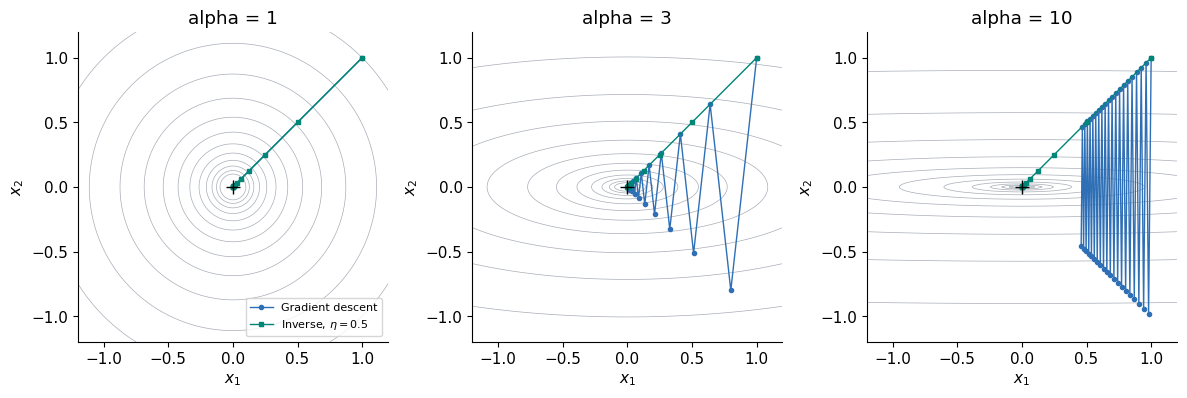

| alpha | best fixed eta | gradient descent steps | inverse steps |
|---|---|---|---|
| 1 | 0.5000 | 1 | 11 |
| 3 | 0.1000 | 33 | 11 |
| 10 | 0.0099 | 363 | 11 |

In [2]:
def steps_to_tolerance(update, x0, tol=1e-3, limit=10_000):
    x, path = np.array(x0, float), [np.array(x0, float)]
    while np.linalg.norm(x) >= tol and len(path) <= limit:
        x = update(x)
        path.append(x)
    return len(path) - 1, np.array(path)

grid = np.linspace(-1.2, 1.2, 241)
X1, X2 = np.meshgrid(grid, grid)
rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.9))
for ax, alpha in zip(axes, [1, 3, 10]):
    eta = 1/(1 + alpha**2)
    n_gd, gd_path = steps_to_tolerance(lambda x: x - eta*np.array([2*x[0], 2*alpha**2*x[1]]), [1, 1])
    n_inv, inv_path = steps_to_tolerance(lambda x: 0.5*x, [1, 1])
    rows.append((alpha, eta, n_gd, n_inv))
    ax.contour(X1, X2, X1**2 + alpha**2*X2**2, levels=np.geomspace(0.01, 2*alpha**2, 12),
               colors=INK, linewidths=0.5, alpha=0.4)
    ax.plot(*gd_path[:40].T, 'o-', ms=3, lw=1, color=COLORS['Gradient descent'], label='Gradient descent')
    ax.plot(*inv_path.T, 's-', ms=3, lw=1, color=COLORS['Inverse simulator'], label='Inverse, $\\eta=0.5$')
    ax.plot(0, 0, 'k+', ms=10)
    ax.set(title=f'alpha = {alpha}', xlabel='$x_1$', ylabel='$x_2$', aspect='equal')
axes[0].legend(fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()

table = '| alpha | best fixed eta | gradient descent steps | inverse steps |\n|---|---|---|---|\n'
table += '\n'.join(f'| {a} | {e:.4f} | {g} | {i} |' for a, e, g, i in rows)
display(Markdown(table))

Gradient descent needs 1, 33, and 363 steps, and the count grows like $\alpha^2$. For $\alpha=10$ the path zigzags across the steep direction, and each step removes only 2 percent of the error in both coordinates (the plot shows the first 40 steps). The inverse update with $\eta=0.5$ needs 11 steps for every $\alpha$ and follows the same diagonal.

Units give a second check. If $x_1$ and $x_2$ carry different units, the gradient step $-\eta\,\partial L/\partial x_2$ has the units of $L$ divided by the units of $x_2$. The inverse step $\mathbf y^{-1}(\cdot)-\mathbf x$ has the units of $\mathbf x$. For a linear simulator Newton and the inverse agree. What happens when the simulator is nonlinear?

## 2. A nonlinear simulator

PBDL's example squares the second input,
$$\mathbf y(\mathbf x)=\begin{bmatrix}x_1\\ x_2^2\end{bmatrix},\qquad L(\mathbf y)=\lVert\mathbf y\rVert^2,$$
and starts at $\mathbf x=(3,3)$. The minimum is again $\mathbf x=0$.

Reverse-mode AD computes the gradient in two stages through the output $\mathbf y$. It first computes $\partial L/\partial\mathbf y=2\mathbf y=(6,18)$. Then it multiplies by the transposed Jacobian of the simulator, $J=\partial\mathbf y/\partial\mathbf x=\operatorname{diag}(1,2x_2)$, which is $\operatorname{diag}(1,6)$ at the start,
$$\nabla_{\mathbf x}L=J^T\,\frac{\partial L}{\partial\mathbf y}=\begin{bmatrix}1&0\\0&6\end{bmatrix}\begin{bmatrix}6\\18\end{bmatrix}=\begin{bmatrix}6\\108\end{bmatrix}.$$
The next cell repeats both stages in PyTorch. The vector-Jacobian product `torch.autograd.grad(y, x, grad_outputs=v)` returns $J^T\mathbf v$ without forming $J$.

In [3]:
def simulator(x):
    return torch.stack([x[0], x[1]**2])

def loss_y(y):
    return (y**2).sum()

def loss_x(x):
    return loss_y(simulator(x))

x = torch.tensor([3.0, 3.0], requires_grad=True)
y = simulator(x)
dL_dy = torch.autograd.grad(loss_y(y), y, retain_graph=True)[0]
vjp = torch.autograd.grad(y, x, grad_outputs=dL_dy)[0]
full = torch.autograd.grad(loss_x(x), x)[0]
J = torch.autograd.functional.jacobian(simulator, x.detach())
print('dL/dy      ', dL_dy.numpy())
print('J^T dL/dy  ', vjp.numpy())
print('grad L(x)  ', full.numpy())
print('J\n', J.numpy())

dL/dy       [ 6. 18.]
J^T dL/dy   [  6. 108.]
grad L(x)   [  6. 108.]
J
 [[1. 0.]
 [0. 6.]]


The gradient $(6,108)$ points almost along $x_2$, although the minimum lies along the diagonal. Squaring $x_2$ makes the loss grow like $x_2^4$, so the loss is steep in $x_2$ at the start and flat in $x_2$ near the minimum. Which update copes with both?

## 3. Four updates

Each update proposes a step $\Delta\mathbf x$ from the current point.

| Update | Step $\Delta\mathbf x$ | Needs |
|---|---|---|
| Gradient descent | $-\eta\,\nabla_{\mathbf x}L$ | the gradient |
| Newton | $-\eta\,(\nabla^2_{\mathbf x}L)^{-1}\nabla_{\mathbf x}L$ | the gradient and the Hessian in $\mathbf x$ |
| Inverse gradient | $J^{-1}\Delta\mathbf y$ | the Jacobian of the simulator, inverted |
| Inverse simulator | $\mathbf y^{-1}(\mathbf y+\Delta\mathbf y;\,\mathbf x)-\mathbf x$ | a local inverse of the simulator |

The last two updates first choose a step $\Delta\mathbf y$ in the output space. We take a Newton step on $L(\mathbf y)$, as PBDL does, which gives $\Delta\mathbf y=-\eta\,(\nabla^2_{\mathbf y}L)^{-1}\nabla_{\mathbf y}L=-\eta\,\mathbf y$. The inverse gradient maps $\Delta\mathbf y$ back with the linearization $J^{-1}$. The inverse simulator maps it back with $\mathbf y^{-1}(\cdot\,;\mathbf x)$, the inverse that returns the solution nearest the current $\mathbf x$. Here that inverse is $(y_1,+\sqrt{y_2})$, because $x_2$ starts positive.

Work out one step of each by hand. The loss is $L=x_1^2+x_2^4$, and its Hessian in $\mathbf x$ is $\operatorname{diag}(2,12x_2^2)$. Every update shrinks $x_1$ by a constant factor, and the four updates differ in $x_2$.

- Gradient descent sets $x_2\leftarrow x_2-4\eta x_2^3$. The step is large far from the minimum and vanishes near it.
- Newton sets $x_2\leftarrow(1-\eta/3)\,x_2$, because the Hessian entry $12x_2^2$ divides the gradient entry $4x_2^3$.
- The inverse gradient sets $x_2\leftarrow(1-\eta/2)\,x_2$, because $J^{-1}$ divides $\Delta y_2=-\eta x_2^2$ by $2x_2$.
- The inverse simulator sets $x_2\leftarrow\sqrt{1-\eta}\;x_2$, because it shrinks $y_2$ by the factor $1-\eta$.

The step sizes follow PBDL. They are $\eta=0.01$ for gradient descent, $1/3$ for Newton, and $0.3$ for the two inverse updates, so the first steps are about equally long. With these values the factors on $x_2$ are $8/9$ for Newton, 0.85 for the inverse gradient, and 0.84 for the inverse simulator. Predict where each update is after 10 steps.

The code computes every derivative with PyTorch. The Hessian comes from `torch.autograd.functional.hessian`, and the Jacobian from `torch.autograd.functional.jacobian`.

| Update | first step length | x after 10 steps | distance to 0 | loss |
|---|---|---|---|---|
| Gradient descent | 1.082 | (2.451, 0.962) | 2.633 | 6.8639 |
| Newton | 1.054 | (0.052, 0.924) | 0.925 | 0.7311 |
| Inverse gradient | 1.006 | (0.085, 0.591) | 0.597 | 0.1289 |
| Inverse simulator | 1.025 | (0.085, 0.504) | 0.511 | 0.0718 |


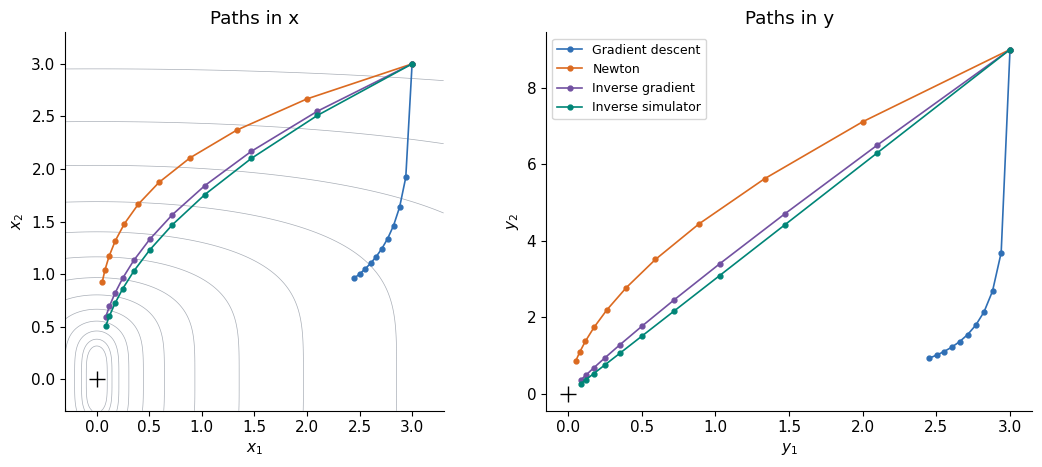

In [4]:
def gradient(f, x):
    x = torch.as_tensor(x).clone().requires_grad_(True)
    return torch.autograd.grad(f(x), x)[0]

def step_gd(x, eta=0.01):
    return x - eta*gradient(loss_x, x)

def step_newton(x, eta=1/3):
    H = torch.autograd.functional.hessian(loss_x, x)
    return x - eta*torch.linalg.solve(H, gradient(loss_x, x))

def step_in_y(x, eta=0.3):
    # Newton step on L(y): -eta * H_y^{-1} grad_y L.
    y = simulator(x)
    H = torch.autograd.functional.hessian(loss_y, y)
    return -eta*torch.linalg.solve(H, gradient(loss_y, y))

def step_inverse_gradient(x, eta=0.3):
    J = torch.autograd.functional.jacobian(simulator, x)
    return x + torch.linalg.solve(J, step_in_y(x, eta))

def inverse_simulator(y_target, x):
    # Local inverse: the root of y(x) = y_target with the sign of the current x_2.
    return torch.stack([y_target[0], torch.sign(x[1])*torch.sqrt(y_target[1])])

def step_inverse_simulator(x, eta=0.3):
    return inverse_simulator(simulator(x) + step_in_y(x, eta), x)

updates = {'Gradient descent': step_gd, 'Newton': step_newton,
           'Inverse gradient': step_inverse_gradient, 'Inverse simulator': step_inverse_simulator}
paths = {}
for name, update in updates.items():
    x = torch.tensor([3.0, 3.0])
    path = [x]
    for _ in range(10):
        x = update(x)
        path.append(x)
    paths[name] = torch.stack(path).numpy()

table = '| Update | first step length | x after 10 steps | distance to 0 | loss |\n|---|---|---|---|---|\n'
for name, path in paths.items():
    final = path[-1]
    table += (f'| {name} | {np.linalg.norm(path[1] - path[0]):.3f} | ({final[0]:.3f}, {final[1]:.3f}) '
              f'| {np.linalg.norm(final):.3f} | {final[0]**2 + final[1]**4:.4f} |\n')
display(Markdown(table))

grid = np.linspace(-0.3, 3.3, 241)
X1, X2 = np.meshgrid(grid, grid)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].contour(X1, X2, X1**2 + X2**4, levels=np.geomspace(0.01, 160, 14), colors=INK,
                linewidths=0.5, alpha=0.4)
for name, path in paths.items():
    axes[0].plot(*path.T, 'o-', ms=3.5, lw=1.2, color=COLORS[name], label=name)
    y_path = np.stack([path[:, 0], path[:, 1]**2], axis=1)
    axes[1].plot(*y_path.T, 'o-', ms=3.5, lw=1.2, color=COLORS[name], label=name)
for ax, space in zip(axes, ['x', 'y']):
    ax.plot(0, 0, 'k+', ms=12)
    ax.set(xlabel=f'${space}_1$', ylabel=f'${space}_2$', title=f'Paths in {space}')
axes[0].set(aspect='equal')
axes[1].legend(fontsize=9)
fig.tight_layout()
plt.show()

Gradient descent ends at $(2.45,0.96)$, 2.63 from the minimum. Its first step is almost all $x_2$, and then its steps in $x_2$ vanish as $x_2^3$ while $x_1$ shrinks by only 0.98 per step. Newton ends 0.925 from the minimum. Its $x_1$ has nearly converged, but $x_2$ shrinks by only $8/9$ per step, because the Hessian entry $12x_2^2$ also vanishes at the minimum. The inverse gradient ends 0.597 away and the inverse simulator 0.511 away.

The right panel shows the same runs in $\mathbf y$. The inverse simulator moves along a straight line, because each step multiplies $\mathbf y$ by $1-\eta=0.7$. Gradient descent and Newton choose their steps in $\mathbf x$, and their paths in $\mathbf y$ bend. The inverse gradient uses the linearization $J^{-1}$, so its path in $\mathbf y$ bends slightly.

Our simulator came with a formula for its inverse. What if it does not?

## 4. A local inverse without a formula

Most simulators have no formula for $\mathbf y^{-1}$, but we can compute the local inverse numerically. Given the target $\mathbf y^\star=\mathbf y(\mathbf x)+\Delta\mathbf y$, solve $\mathbf y(\mathbf x')=\mathbf y^\star$ by Newton's method for roots,
$$\mathbf x'\leftarrow\mathbf x'-J(\mathbf x')^{-1}\big(\mathbf y(\mathbf x')-\mathbf y^\star\big),$$
starting at $\mathbf x'=\mathbf x$. The first iteration is the inverse gradient step. Later iterations add the higher-order terms that the linearization drops. Starting at the current point makes the solve return the root nearest that point, which is the local inverse.

In [5]:
def numerical_inverse(y_target, x, iterations):
    x_new = x.clone()
    for _ in range(iterations):
        J = torch.autograd.functional.jacobian(simulator, x_new)
        x_new = x_new - torch.linalg.solve(J, simulator(x_new) - y_target)
    return x_new

rows = []
for iterations in [1, 2, 3, 5]:
    x = torch.tensor([3.0, 3.0])
    for _ in range(10):
        x = numerical_inverse(simulator(x) + step_in_y(x), x, iterations)
    gap = np.abs(x.numpy() - paths['Inverse simulator'][-1]).max()
    rows.append((iterations, np.linalg.norm(x.numpy()), gap))
table = '| root iterations per step | distance to 0 after 10 steps | gap to the formula inverse |\n|---|---|---|\n'
table += '\n'.join(f'| {i} | {d:.3f} | {g:.1e} |' for i, d, g in rows)
display(Markdown(table))

x = torch.tensor([3.0, -3.0])
for _ in range(10):
    x = numerical_inverse(simulator(x) + step_in_y(x), x, 5)
print(f'start (3, -3), x after 10 steps: ({x[0]:.3f}, {x[1]:.3f})')

| root iterations per step | distance to 0 after 10 steps | gap to the formula inverse |
|---|---|---|
| 1 | 0.597 | 8.6e-02 |
| 2 | 0.512 | 6.3e-04 |
| 3 | 0.511 | 3.9e-08 |
| 5 | 0.511 | 1.1e-16 |

start (3, -3), x after 10 steps: (0.085, -0.504)


One root iteration per step reproduces the inverse gradient, 0.597 from the minimum. Five iterations match the formula inverse to rounding error. Each outer step now costs several simulator runs and Jacobian solves. Started at $(3,-3)$, the same solve returns the negative root and walks to the minimum from below.

## 5. When inversion fails

Inversion needs a square Jacobian that we can invert. A network maps millions of weights to one scalar loss, so $\partial L/\partial\boldsymbol\theta$ is a single row and has no inverse. PBDL's later chapters keep gradient descent for the network weights and use inverse-simulator steps only for the physics ([scale-invariant physics training](https://www.physicsbaseddeeplearning.org/physgrad-nn.html), [half-inverse gradients](https://www.physicsbaseddeeplearning.org/physgrad-hig.html)).

An inverse can also exist and still be unusable. Heat flow on a ring multiplies mode $k$ by $e^{-\nu k^2T}$, as in the [heat-flow lesson](https://kks32-courses.github.io/sciml/05-fno/fno-intuition.html). Its inverse multiplies mode $k$ by $e^{\nu k^2T}$.

In [6]:
NU_T = 0.091
k = np.arange(13)
print(f'inverse heat factor at k = 12: {np.exp(NU_T*k[-1]**2):.2e}')

inverse heat factor at k = 12: 4.91e+05


With $\nu T=0.091$ the inverse factor at $k=12$ is $4.9\times10^5$. A measurement error of $10^{-6}$ in that mode becomes an error of about 0.5 in the recovered initial temperature. The inverse of heat flow exists, and an update built on it amplifies noise. Where in a physics-based model can we afford an inverse, and where must we fall back on the gradient?

## Exercises

1. Set $\alpha=100$ in Section 1. Predict the number of gradient descent steps with the best fixed step, then check.
2. Replace $y_2=x_2^2$ with $y_2=x_2^3$. Derive the factor that each of the four updates applies to $x_2$, then rerun Section 3.
3. Add noise of size $10^{-3}$ to $\Delta\mathbf y$ in the inverse gradient. Which coordinate suffers first as $x_2\to0$, and why?
4. Run Newton with $\eta=1$. How many steps does it need to bring $x_2$ below $10^{-3}$?

This notebook follows the PBDL chapter [Scale-Invariance and Inversion](https://www.physicsbaseddeeplearning.org/physgrad.html) and its [comparison example](https://www.physicsbaseddeeplearning.org/physgrad-comparison.html), which build on [Holl, Koltun, and Thuerey](https://arxiv.org/abs/2109.15048).